# Retail Analytics Platform

## Phase 5 - Customer Churn Analytics

### Objective

Identify potentially churned customers using transactional and RFM metrics.

### Business Problem

Customer churn negatively impacts revenue and customer lifetime value. Early identification of at-risk customers enables proactive retention strategies.

### Churn Indicators

- High Recency
- Low Purchase Frequency
- Low Revenue Contribution
- Declining Purchase Activity

### Outputs

- churn_analysis.csv
- churn_summary.csv

In [15]:
# ============================================================
# RETAIL ANALYTICS PLATFORM
# PHASE 5 - CUSTOMER CHURN ANALYTICS
# ============================================================

from datetime import datetime
import pandas as pd
import numpy as np
import warnings
import time
from pathlib import Path

warnings.filterwarnings("ignore")

print("=" * 60)
print("STARTING CUSTOMER CHURN ANALYTICS")
print("=" * 60)

start_time = time.time()
run_timestamp = datetime.now()

print(f"Execution Started : {run_timestamp}")

STARTING CUSTOMER CHURN ANALYTICS
Execution Started : 2026-10-29 09:29:59.532820


In [16]:
# ============================================================
# LOAD RFM DATA
# ============================================================

RFM_FILE = "../data/processed/rfm_customer_segmentation.csv"

print(f"Loading file: {RFM_FILE}")

rfm_df = pd.read_csv(RFM_FILE)

print("\nDataset Shape")
print(rfm_df.shape)

display(rfm_df.head())

Loading file: ../data/processed/rfm_customer_segmentation.csv

Dataset Shape
(6, 9)


,Customer_ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,CUST001,0,3,122000,3,3,3,333,Champions
1,CUST002,3,2,30000,2,2,2,222,Potential Loyalists
2,CUST003,2,2,93000,2,3,3,233,Loyal Customers
3,CUST004,5,1,12000,1,1,1,111,At Risk
4,CUST005,4,1,35000,1,1,2,112,At Risk


In [17]:
# ============================================================
# DATA VALIDATION
# ============================================================

print("Checking Missing Values")

missing_values = rfm_df.isnull().sum()

display(missing_values)

assert len(rfm_df) > 0, "Dataset is empty."

print("\nValidation Passed")

Checking Missing Values


Customer_ID    0
Recency        0
Frequency      0
Monetary       0
R_Score        0
F_Score        0
M_Score        0
RFM_Score      0
Segment        0
dtype: int64


Validation Passed


In [18]:
# ============================================================
# CHURN CLASSIFICATION
# ============================================================

print("Creating Churn Categories...")

conditions = [
    (rfm_df["Recency"] >= 5),
    (rfm_df["Recency"] >= 3) & (rfm_df["Recency"] < 5),
    (rfm_df["Recency"] < 3)
]

choices = [
    "High Risk",
    "Medium Risk",
    "Low Risk"
]

rfm_df["Churn_Status"] = np.select(
    conditions,
    choices,
    default="Unknown"
)

display(
    rfm_df[
        [
            "Customer_ID",
            "Recency",
            "Segment",
            "Churn_Status"
        ]
    ]
)

print("\nChurn Classification Completed")

Creating Churn Categories...


,Customer_ID,Recency,Segment,Churn_Status
0,CUST001,0,Champions,Low Risk
1,CUST002,3,Potential Loyalists,Medium Risk
2,CUST003,2,Loyal Customers,Low Risk
3,CUST004,5,At Risk,High Risk
4,CUST005,4,At Risk,Medium Risk
5,CUST006,1,Loyal Customers,Low Risk



Churn Classification Completed


In [19]:
# ============================================================
# CHURN SUMMARY
# ============================================================

print("Generating Churn Summary...")

churn_summary = (
    rfm_df["Churn_Status"]
    .value_counts()
    .reset_index()
)

churn_summary.columns = [
    "Churn_Status",
    "Customer_Count"
]

display(churn_summary)

Generating Churn Summary...


,Churn_Status,Customer_Count
0,Low Risk,3
1,Medium Risk,2
2,High Risk,1


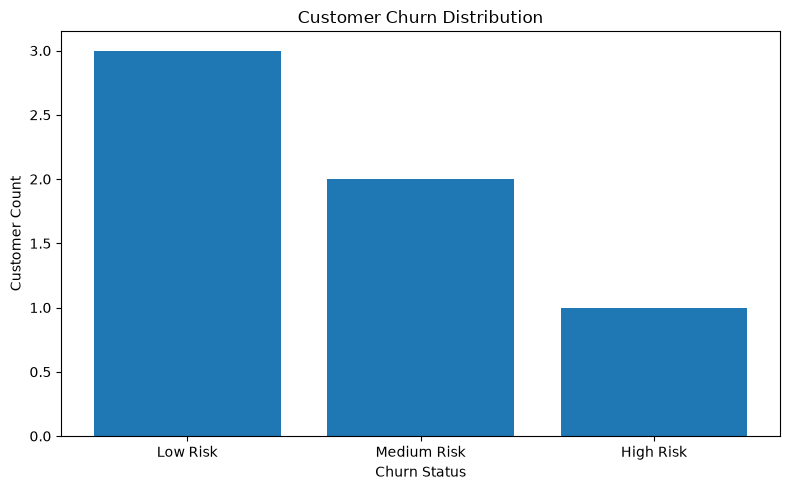

Visualization Generated Successfully


In [20]:
# ============================================================
# VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    churn_summary["Churn_Status"],
    churn_summary["Customer_Count"]
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Customer Count")

plt.tight_layout()

plt.show()

print("Visualization Generated Successfully")

In [21]:
# ============================================================
# SAVE OUTPUT FILES
# ============================================================

print("Saving Output Files...")

output_path = Path("../data/processed")

churn_file = output_path / "churn_analysis.csv"
summary_file = output_path / "churn_summary.csv"

rfm_df.to_csv(churn_file, index=False)
churn_summary.to_csv(summary_file, index=False)

print("\nFiles Saved Successfully")

print(churn_file)
print(summary_file)

Saving Output Files...

Files Saved Successfully
..\data\processed\churn_analysis.csv
..\data\processed\churn_summary.csv


In [22]:
# ============================================================
# EXECUTION SUMMARY
# ============================================================

end_time = time.time()

duration = round(
    (end_time - start_time) / 60,
    2
)

print("=" * 60)
print("CUSTOMER CHURN ANALYTICS COMPLETED")
print("=" * 60)

print(f"Execution Time : {duration} Minutes")
print(f"Records Processed : {len(rfm_df)}")

print("\nOutput Files Generated:")
print("1. churn_analysis.csv")
print("2. churn_summary.csv")

print("\nPhase 5 Completed Successfully")

CUSTOMER CHURN ANALYTICS COMPLETED
Execution Time : 0.02 Minutes
Records Processed : 6

Output Files Generated:
1. churn_analysis.csv
2. churn_summary.csv

Phase 5 Completed Successfully
